# Do grokking and double descent happen in XGBoost?




To find out whether these phenomena really happen in XGBoost, I trained 580 XGBoost models and saved everything about each one. This notebook reads those saved runs and turns them into tables and figures.

### How I designed the experiments

I used two kinds of data:
- **Synthetic data:** data I generate myself from a known rule, so I know the right answer and can control how hard the task is.
- **Real data:** datasets collected in practice, to check whether what I see on synthetic data also happens in real use.

#### Synthetic tasks

**1. Sparse parity (for grokking)**
- In sparce parity, each example is a row of 20 random bits (0 or 1, like coin flips). Three of these bits are "hidden": the label depends only on them. The label is the parity of the hidden bits: count how many of them are 1, and the label is 1 if that count is odd and 0 if it is even."Sparse" means only a few of the 20 bits matter. The model is not told which bits are hidden.
- *Example.* Take 6 bits with hidden bits x2, x4 and x5. In the row 1 0 1 1 0 0, the hidden bits are 0, 1 and 0. That is one 1, an odd number, so the label is 1.
- *Why it is hard.* Looking at any single bit, or any two bits, tells you nothing about the label. Only all three together do. A decision tree chooses each split by looking at one feature at a time, so nothing guides it toward the hidden bits: it finds them only by luck.
- *Why I use it.* Sparse parity is a standard test task for studying sudden and delayed learning. [Barak et al. (2022)](https://arxiv.org/abs/2207.08799) used it to show that neural networks learn it in sudden jumps after long flat periods. [Merrill et al. (2023)](https://arxiv.org/abs/2303.11873) studied grokking on it directly, and [Miller et al. (2024)](https://arxiv.org/abs/2310.17247) used it among their tasks when showing that grokking also happens in models that are not neural networks. Because I know the hidden bits, I can also see exactly when a tree finds them.
- *Setup.* 100, 300 or 1000 training examples. Grokking should need few examples, because the model has to memorize them before it finds the pattern. Test accuracy is measured on 10,000 new examples the model never saw.

**2. Friedman function with flipped labels (for double descent)**
- Friedman function is a standard test function proposed by Jerome Friedman (1991) for testing regression methods. Each example has five inputs x1 to x5, each a random number between 0 and 1, and y = 10 sin(π x1 x2) + 20 (x3 − 0.5)² + 10 x4 + 5 x5. It mixes an interaction (x1 times x2), a curve (x3) and straight-line effects (x4, x5).
- *How I made it a classification task.* The label is 1 if y is above its median and 0 otherwise. That gives two classes of equal size, and the label is fully decided by the inputs, so a perfect model could reach 100%. I added 15 columns of random numbers that carry no information (20 features in total) and shuffled the order of the columns.
- *Flipped labels.* I deliberately changed 20% of the training labels to the wrong class. Double descent over training time is known to appear mainly when some labels are wrong: memorizing them pushes test error up. I also ran it with 0% flipped labels as a control. Test labels are never flipped.
- *Setup.* 2,000 training examples and 10,000 test examples.

**3. `make_classification` (for double descent)**
- make_classification is a function in scikit-learn that generates random classification data. Each class is made of a few clouds of points in a space of 20 features, 10 of which carry information. Unlike the Friedman task, the classes overlap a little, so even a perfect model makes some mistakes.

**4. Modular addition (for feature learning)**
- "x mod 31" is the remainder after dividing x by 31. For example, (20 + 15) mod 31 = 35 − 31 = 4. The inputs are two numbers a and b from 0 to 30, and the label is (a + b) mod 31, so there are 31 possible labels and 961 possible pairs. I train on half of the pairs and test on the other half, which the model never saw.
- *Why it tests feature learning.* Knowing only a tells you nothing about the label: every label is still equally likely. The same holds for b. To get an unseen pair right, the model has to build a feature that combines a and b, such as a + b. Neural networks are known to learn such features on this task, and grokking was first observed on tasks like it (Power et al., 2022). - *Five ways of writing a and b.* I gave XGBoost the two numbers in five different forms, from simple (two integers) to the form neural networks are known to learn (sines and cosines), plus one control that includes the answer's key feature, a + b. Section 4 explains each one.

#### Real datasets

Five datasets from **TabArena**. Each has at least 6,000 rows, so the test sets are large enough to see small changes. Each was run with 0% and with 20% flipped training labels, using 2,000 training rows.

- **heloc (finance, 10,459 rows).** Home equity loan applications from FICO's Explainable Machine Learning Challenge. The label is whether the applicant was ever 90 or more days late on a payment within two years, predicted from 23 credit-report features.
- **E-CommereShippingData (business, 10,999 rows).** Shipments from an online shop; the label is whether a shipment arrived late, predicted from 10 features such as shipping mode, product cost, discount and weight. TabArena notes the label is only weakly related to the features, so accuracy is low for every model.
- **in_vehicle_coupon_recommendation (marketing, 12,684 rows).** Survey answers on whether a driver would accept a coupon (for example, for a coffee house or bar), predicted from 24 mostly categorical features describing the driving scenario, the coupon and the person.
- **NATICUSdroid (cybersecurity, 7,491 rows).** Android apps described by which of 86 permissions they request (yes/no each); the label is whether the app is malware.
- **SDSS17 (astronomy, 78,053 rows).** Sky objects from the Sloan Digital Sky Survey, labelled galaxy, star or quasar, from their position, brightness in five colour filters, redshift and observation IDs. I set it aside for now because of those ID columns (section 5).





### What I compared

To build each tree, XGBoost gives every training row a *hessian*: a number that says how much the loss still cares about that row. For classification it equals p(1 − p), where p is the predicted probability, so it is about 0.25 when the model is unsure and close to 0 once the model is confident. Two XGBoost settings use the hessian, and I call them **the brakes**:
- **`min_child_weight`** (default 1): a split is allowed only if each side of it has a hessian sum of at least this value. Once the model is confident, the hessians are tiny, so most splits are blocked.
- **`lambda`** (default 1): it is added to the hessian sum when each leaf's value is computed. When the hessians are tiny, it shrinks the tree's corrections.

I trained every task twice: with the **default** settings (both 1) and with the **brakes off** (both 0). My hypothesis (RQ2) is that these two settings decide whether learning can continue after the model has memorized its training data.

On parity, I added a third setting, **brakes off + weights x1000**. XGBoost also refuses any split whose gain is at most 10⁻⁶, a fixed number in its code that no setting can change. Multiplying every sample weight by 1000 makes all gains 1000 times larger, which effectively lowers this floor without changing anything else.

### How I kept the comparison fair
- Every setting is trained on exactly the same data, and each experiment is repeated with 10 or 20 different random draws of the data (seeds).
- No early stopping: every model trains to the end (1,667 or 5,000 rounds), so I can see the whole curve.
- Test labels are never flipped, so test accuracy always measures real generalization.
- Everything else is fixed: XGBoost 3.4.1, the same tree type, and no random subsampling.

### The followings were saved from every run:
Training, validation and test accuracy and log loss after every round, statistics for every tree, the trained model and the exact data split. This lets me compute new measures later without training again.



## Main results

**1. Grokking happens in XGBoost, but rarely.**
On sparse parity, 18 of 120 runs with the brakes off grokked, all of them with only 100 or 300 training rows. With the default settings, 2 of 60 runs did. The brakes matter even more for whether the pattern is learned at all: with 100 training rows, the default model stayed at chance, while the brakes-off models reached 78 to 84% test accuracy.

**2. Double descent happens too, but it is small and needs wrong labels.** On the Friedman task with 20% of labels flipped, 6 of 20 runs with the brakes off showed it, and none of the 20 default runs. The dip is about 1 accuracy point and comes right after the model memorizes the flipped labels, as theory predicts. Without flipped labels, it never appeared. On the four real datasets, it appeared in only 2 of 160 runs: test accuracy simply peaked early and then fell as the wrong labels were memorized.

**3. There is no sign of feature learning.** On modular addition, XGBoost memorized the training pairs but got unseen pairs right no more often than chance, whichever way the numbers were written. Given the a + b column, it scored 98 to 99%, so it can learn the task, but it does not build the needed feature itself.

**Two things I learned along the way**
- **There is a third brake.** Even with both brakes off, learning eventually stops, because XGBoost refuses any split whose gain is at most 10⁻⁶. My proposal missed this, and the model of when learning freezes (RQ2) has to include it.
- **On noisy data, training longer never paid off.** The default model's early peak was never beaten by any late improvement. This matters for early stopping (RQ3).

*The real-data results leave out SDSS17 (see section 5).*

## Setup



In [2]:
# Connect to Google Drive and load the results of every finished run (takes about 2 minutes)
from google.colab import drive
drive.mount('/content/drive')

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path('/content/drive/MyDrive/xgb-grokking')     # folder with xgbgrok.py and the results
RUNS_DIR = ROOT / 'results/stage1a'                    # where the 580 runs are saved
DATA_DIR = ROOT / 'data/raw'                           # the downloaded real datasets
FIG_DIR = ROOT / 'figures/stage1a_analysis'            # figures from this notebook go here
FIG_DIR.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(ROOT))
import xgbgrok

runs = pd.read_csv(ROOT / 'results/summary/stage1a_runs.csv', dtype={'run_id': str})   # one row per run
print(len(runs), 'runs loaded')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
580 runs loaded


In [3]:
# Names and colours used in every table and figure. Edit them here.
SETTING_NAMES = {
    'default': 'Default',
    'brakes_off': 'Brakes off',
    'brakes_off_w1e3': 'Brakes off + weights x1000',
}
SETTING_COLORS = {
    'default': '#eb6834',           # orange
    'brakes_off': '#1baf7a',        # green
    'brakes_off_w1e3': '#2a78d6',   # blue
}
TASK_NAMES = {
    'parity': 'Sparse parity',
    'friedman': 'Friedman',
    'skl_classification': 'Pilot 3 repeat',
    'modadd': 'Modular addition',
    'openml': 'Real datasets',
}
ENCODING_NAMES = {
    'onehot': 'One-hot',
    'integers': 'Two integers',
    'categorical': 'Native categorical',
    'sincos': 'Sines and cosines',
    'aplusb': 'Integers + a+b\n(control)',
}
SET_ASIDE = ['SDSS17']   # datasets left out of the main results (see section 5)

# keep the settings in this order in every table
runs['setting'] = pd.Categorical(runs['setting'], categories=list(SETTING_NAMES))

In [4]:
# Helper functions for the tables and figures. You don't need to change anything here.

plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e4e3df', 'legend.frameon': False,
})


def load_curve(run_ids, column):
    # Read one saved curve (for example 'test_error') for several runs.
    # Returns the round numbers and an array with one row per run.
    curves = [pd.read_parquet(RUNS_DIR / 'runs' / r / 'curves.parquet', columns=['round', column])
              for r in run_ids]
    rounds = curves[0]['round'].to_numpy()
    values = np.stack([c[column].to_numpy() for c in curves])
    return rounds, values


def plot_median(ax, rounds, values, color, label, dashed=False, band=True):
    # Draw the median over seeds; the shaded band covers the middle 50% of seeds.
    low, middle, high = np.percentile(values, [25, 50, 75], axis=0)
    ax.plot(rounds, middle, '--' if dashed else '-', color=color, lw=1.2 if dashed else 2, label=label)
    if band:
        ax.fill_between(rounds, low, high, color=color, alpha=0.15, linewidth=0)


def how_many(flags):
    # Count True values, written as '3/20'.
    flags = flags.dropna().astype(bool)
    return f'{flags.sum()}/{len(flags)}'


def show_table(table, decimals=3):
    display(table.style.hide(axis='index').format(precision=decimals, na_rep='-'))

## 1. Experiment settings

| Task | Training data | Depth | Learning rate | Rounds | Seeds | Runs |
|---|---|---|---|---|---|---|
| Sparse parity | 100, 300 or 1000 rows | 3 | 0.1 | 5,000 | 20 | 180 |
| Friedman | 2,000 rows; 0% or 20% labels flipped | 6 | 0.3 | 1,667 | 20 | 80 |
| `make_classification` (Pilot 3 repeat) | 2,000 rows; 20% flipped | 6 | 0.3 | 1,667 | 10 | 20 |
| Modular addition | 480 of the 961 pairs; 5 input forms | 6 | 0.3 | 1,667 | 10 | 100 |
| 5 real datasets | 2,000 rows; 0% or 20% flipped | 6 | 0.3 | 1,667 | 10 | 200 |
| **Total** | | | | | | **580** |



## 2. Grokking

Does XGBoost memorize its training data first and only much later do well on new data?

To measure it, I used sparse parity. Its label depends on 3 hidden bits together, and no single bit says anything about it, so a tree only does well on new data once it happens to split on all three. A run counts as grokking if test accuracy reaches 0.9 at least twice as late as, and at least 100 rounds after, the run memorized. Test accuracy must also stay around 0.9 for the next 50 rounds, so one lucky round doesn't count.

In [5]:
# Table 1: grokking on sparse parity, by number of training rows and setting
parity = runs[runs.task == 'parity']

rows = []
for (n, setting), group in parity.groupby(['data_n', 'setting'], observed=True):
    rows.append({
        'training rows': int(n),
        'setting': SETTING_NAMES[setting],
        'runs that grokked': how_many(group['grok']),
        'best test accuracy (median)': group['best_test_acc'].median(),
        'final test accuracy (median)': group['final_test_acc'].median(),
        'round memorized (median)': group['t_mem'].median(),
    })
table1 = pd.DataFrame(rows)
table1['round memorized (median)'] = table1['round memorized (median)'].round().astype('Int64')
show_table(table1)

training rows,setting,runs that grokked,best test accuracy (median),final test accuracy (median),round memorized (median)
100,Default,0/20,0.525,0.514,87
100,Brakes off,5/20,0.780,0.714,60
100,Brakes off + weights x1000,6/20,0.837,0.785,60
300,Default,1/20,0.824,0.726,234
300,Brakes off,3/20,1.000,1.000,266
300,Brakes off + weights x1000,4/20,1.000,0.998,266
1000,Default,1/20,1.000,1.000,280
1000,Brakes off,0/20,1.000,1.000,222
1000,Brakes off + weights x1000,0/20,1.000,1.000,222


As you can see, with only 100 training rows, the brakes make all the difference. With the default settings, XGBoost never gets past random guessing. With the brakes off, it sometimes finds the hidden pattern long after it has memorized its training data, which is exactly what grokking is. With 300 rows, the default model gets part of the way (82% at best) but then slowly loses it, while the brakes-off models reach 100% and stay there. With 1000 rows, there is enough data for every setting to find the pattern before it finishes memorizing, so nothing is delayed and there is nothing to grok.

So grokking in XGBoost needs two things at once: little data, so that memorizing comes first, and no brakes, so that learning can continue afterwards. Even then, it happened in only 3 to 6 of every 20 runs. That fits my idea that finding the hidden bits is mostly a matter of luck.

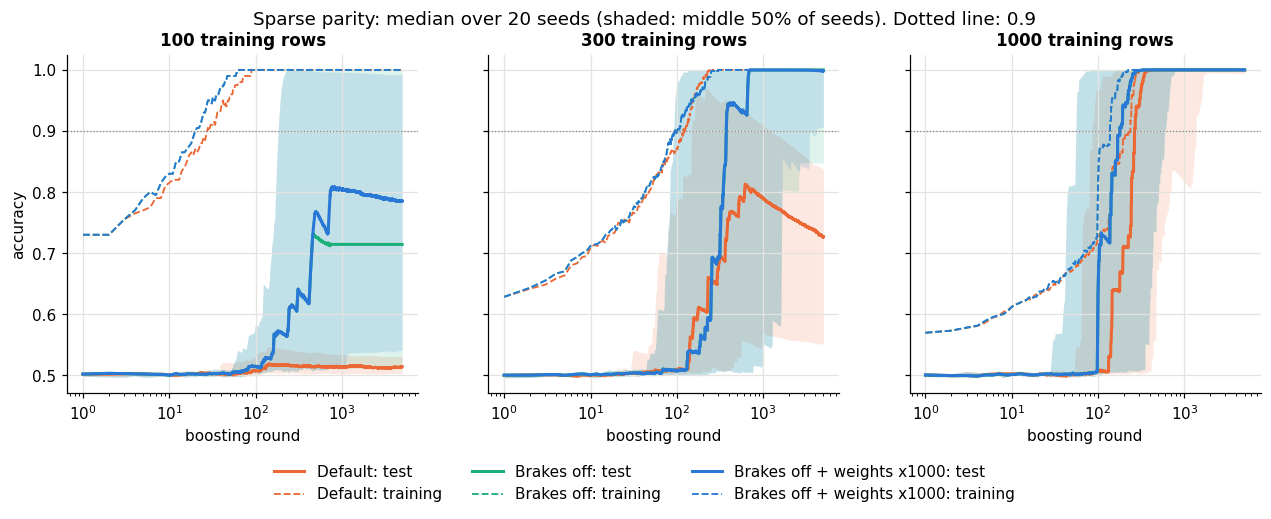

In [6]:
# Figure 1: training and test accuracy over the rounds, for each number of training rows
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

for ax, n in zip(axes, [100, 300, 1000]):
    for setting in SETTING_NAMES:
        ids = parity[(parity['data_n'] == n) & (parity['setting'] == setting)]['run_id']
        if len(ids) == 0:
            continue
        rounds, test_error = load_curve(ids, 'test_error')
        rounds, train_error = load_curve(ids, 'train_error')
        name, color = SETTING_NAMES[setting], SETTING_COLORS[setting]
        plot_median(ax, rounds, 1 - test_error, color, name + ': test')
        plot_median(ax, rounds, 1 - train_error, color, name + ': training', dashed=True, band=False)
    ax.axhline(0.9, color='grey', lw=0.8, ls=':')    # grokking threshold
    ax.set_xscale('log')
    ax.set_xlabel('boosting round')
    ax.set_title(f'{n} training rows')

axes[0].set_ylabel('accuracy')
fig.legend(*axes[0].get_legend_handles_labels(), loc='upper center', bbox_to_anchor=(0.5, -0.02), ncol=3)
fig.suptitle('Sparse parity: median over 20 seeds (shaded: middle 50% of seeds). Dotted line: 0.9')
fig.savefig(FIG_DIR / 'fig1_parity.png', dpi=150, bbox_inches='tight')
plt.show()

In **Figure 1**, dashed lines show training accuracy and solid lines show test accuracy. The x-axis is on a log scale, so each step to the right means 10 times more rounds. The shaded areas show where the middle half of the 20 runs lie, and the dotted line marks 0.9, the grokking threshold.

**What I see.** In every panel, training accuracy (dashed) reaches 100% first. What happens to test accuracy afterwards depends on the data size and the brakes:
- **100 rows:** with the default settings, test accuracy stays flat at 50%, so the model never learns the pattern. With the brakes off, test accuracy only starts to climb after about round 200, long after the training data was memorized (around round 60 to 90). That late climb is what grokking looks like. The shaded area is very wide because runs differ a lot: some reach almost 100%, others stay near 50%.
- **300 rows:** the default model's test accuracy rises to about 80% and then slowly falls. With the brakes off, it jumps to 100%.
- **1000 rows:** training and test accuracy rise together. The model finds the pattern while it is still memorizing, so there is no delay.

The median curve is not itself a grokking curve, because only some of the runs grok. Figure 2 shows one run that does.

*Where the two brakes-off settings give the same curve, the green line is hidden under the blue one.*

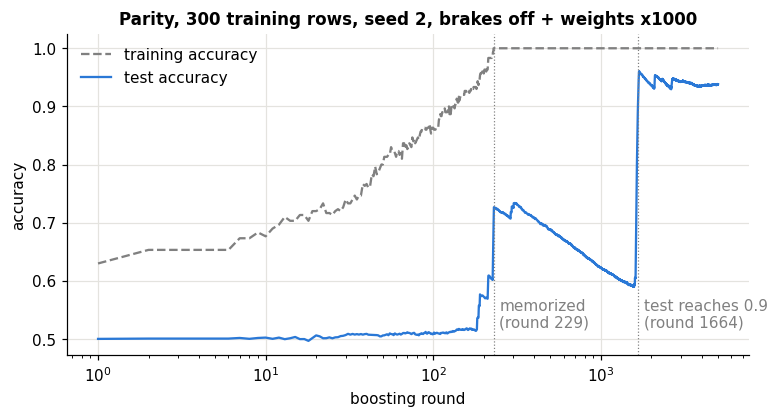

In [7]:
# Figure 2: one run that grokked, the one with the longest delay.
# To show another run, change the line that picks `example`.
grokked = parity[parity['grok'] == True]
example = grokked.assign(delay=grokked['t_reach'] - grokked['t_mem']).sort_values('delay').iloc[-1]
curve = pd.read_parquet(RUNS_DIR / 'runs' / example['run_id'] / 'curves.parquet')

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(curve['round'], 1 - curve['train_error'], '--', color='grey', label='training accuracy')
ax.plot(curve['round'], 1 - curve['test_error'], color=SETTING_COLORS[example['setting']], label='test accuracy')
ax.axvline(example['t_mem'], color='grey', lw=0.8, ls=':')
ax.axvline(example['t_reach'], color='grey', lw=0.8, ls=':')
ax.text(example['t_mem'] * 1.08, 0.52, f"memorized\n(round {int(example['t_mem'])})", color='grey')
ax.text(example['t_reach'] * 1.08, 0.52, f"test reaches 0.9\n(round {int(example['t_reach'])})", color='grey')
ax.set_xscale('log')
ax.set_xlabel('boosting round')
ax.set_ylabel('accuracy')
ax.set_title(f"Parity, {int(example['data_n'])} training rows, seed {example['seed']}, "
             f"{SETTING_NAMES[example['setting']].lower()}")
ax.legend(loc='upper left')
fig.savefig(FIG_DIR / 'fig2_grokking_example.png', dpi=150, bbox_inches='tight')
plt.show()

**Figure 2** shows a single run that grokked: 300 training rows, seed 2, brakes off + weights x1000.
- **Memorizing.** Training accuracy (dashed) climbs steadily and reaches 100% at round 229. Up to then, test accuracy stays at about 50%, the level of random guessing.
- **Getting worse on new data.** Right after memorizing, test accuracy jumps to about 73%, but then slowly falls to about 59% over the next 1,400 rounds. The model is still changing, but nothing it learns works on new data.
- **The sudden jump.** At round 1,664, about 7 times later than it memorized, test accuracy jumps to 96% in a single step, and it stays around 94% to the end. This is grokking: the model memorized first and generalized much later.

The jump happens in one round, not gradually. That fits my idea that one lucky tree finally splits on all three hidden bits, which RQ2 will test directly. It also matters for early stopping (RQ3): a rule that stops once test or validation accuracy stops improving would have stopped soon after round 229, at about 73%, and missed the jump to 96%.

**Takeaway.** Grokking does happen in XGBoost. What I observed: 18 of 120 runs with the brakes off, and 2 of 60 with the default settings. It needs few training rows, so that memorizing comes first, and the brakes off, so that learning can continue afterwards. This confirms what I mentioned in Proposal.

## 3. Double descent

As trees are added, does test error go down, up, and then down again?

Double descent over training time is known to need wrong labels: memorizing them pushes test error up. So I flipped 20% of the training labels, kept the test labels correct, and used 0% as a control. A run counts as double descent if its test error (smoothed over 11 rounds) rises at least 1 point above its best value so far, and then falls at least 1 point again. It is *strong* if the second low point is lower than the first. For small test sets the threshold is larger than 1 point, so noise doesn't count.

In [8]:
# Table 2: how many runs showed double descent
noisy = runs[runs['task'].isin(['friedman', 'skl_classification', 'openml'])]
noisy = noisy[~noisy['data_name'].isin(SET_ASIDE)]
noisy = noisy.assign(name=noisy['data_name'].fillna(noisy['task'].map(TASK_NAMES)))

rows = []
for (name, noise, setting), group in noisy.groupby(['name', 'noise', 'setting'], observed=True):
    rows.append({
        'task': name,
        'flipped labels': f'{noise:.0%}',
        'setting': SETTING_NAMES[setting],
        'double descent': how_many(group['err_dd']),
        'strong': how_many(group['err_strong_dd']),
    })
show_table(pd.DataFrame(rows))

task,flipped labels,setting,double descent,strong
E-CommereShippingData,0%,Default,0/10,0/10
E-CommereShippingData,0%,Brakes off,0/10,0/10
E-CommereShippingData,20%,Default,0/10,0/10
E-CommereShippingData,20%,Brakes off,0/10,0/10
Friedman,0%,Default,0/20,0/20
Friedman,0%,Brakes off,0/20,0/20
Friedman,20%,Default,0/20,0/20
Friedman,20%,Brakes off,6/20,4/20
NATICUSdroid,0%,Default,0/10,0/10
NATICUSdroid,0%,Brakes off,0/10,0/10






- **No wrong labels, no double descent.** With 0% flipped labels, no run showed it, on any task or setting. This fits the idea that the bump in test error comes from the model memorizing wrong labels.
- **Wrong labels alone are not enough.** With 20% flipped labels, the default settings showed it in only 1 of 70 runs. With the brakes off, it showed up in 9 of 70. So, as with grokking, the brakes seem to hold it back.
- **Friedman shows it most clearly.** 6 of 20 brakes-off runs had double descent, and 4 of those were strong: the model ended up better after the bump than before it.
- **It almost never happens on real data.** Only heloc showed it, in 2 of 10 brakes-off runs, and neither was strong. On the other real datasets, test error rose once the model memorized the flipped labels and then stayed up.


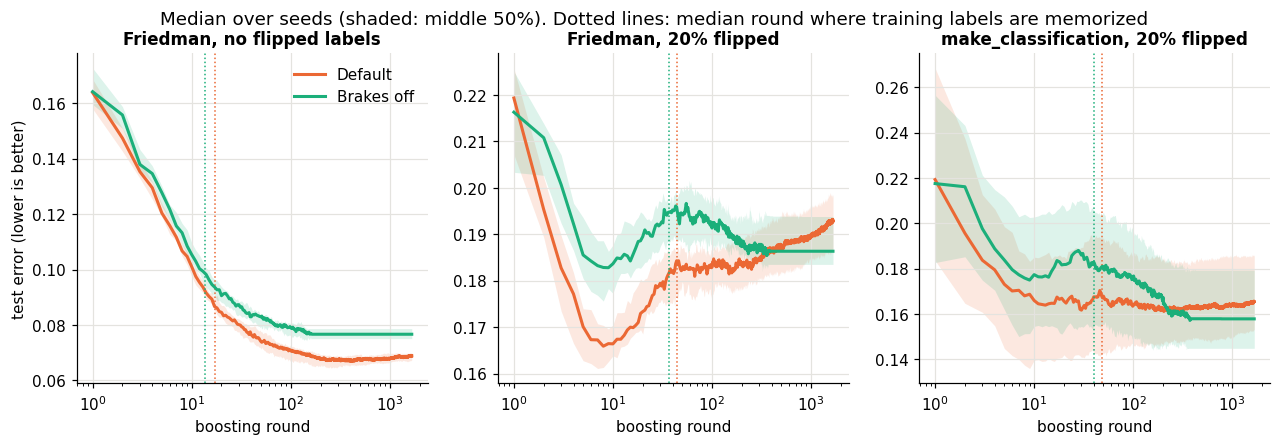

In [13]:
# Figure 3: test error over the rounds on the two synthetic tasks
panels = [
    ('friedman', 0.0, 'Friedman, no flipped labels'),
    ('friedman', 0.2, 'Friedman, 20% flipped'),
    ('skl_classification', 0.2, 'make_classification, 20% flipped'),
]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))

for ax, (task, noise, title) in zip(axes, panels):
    for setting in ['default', 'brakes_off']:
        group = runs[(runs['task'] == task) & (runs['noise'] == noise) & (runs['setting'] == setting)]
        if len(group) == 0:
            continue
        rounds, test_error = load_curve(group['run_id'], 'test_error')
        plot_median(ax, rounds, test_error, SETTING_COLORS[setting], SETTING_NAMES[setting])
        ax.axvline(group['t_mem'].median(), color=SETTING_COLORS[setting], lw=1, ls=':')   # memorized
    ax.set_xscale('log')
    ax.set_xlabel('boosting round')
    ax.set_title(title)

axes[0].set_ylabel('test error (lower is better)')
axes[0].legend(loc='upper right')
fig.suptitle('Median over seeds (shaded: middle 50%). Dotted lines: median round where training labels are memorized')
fig.savefig(FIG_DIR / 'fig3_double_descent.png', dpi=150, bbox_inches='tight')
plt.show()

In **Figure 3**, the x-axis is on a log scale, so the early rounds get more space. The dotted lines mark the median round where the model has memorized the training labels. If double descent happens, it should show up as a bump in test error just after these lines.

**What we can see**

- **Left (Friedman, no flipped labels):** test error falls smoothly and never goes back up. This is the control: with no wrong labels, there is no bump. The green line goes flat after about round 150 because the brakes-off models stop adding new splits.
- **Middle (Friedman, 20% flipped):** the green line (brakes off) is lowest around round 8. It then rises about 1 point to a peak near round 50, just after memorization, and falls again until it levels off around round 300. This is double descent in the median curve. The orange line (default) never falls a second time: after memorization, its test error keeps rising until the last round.
- **The second dip doesn't help.** The best point in this panel is the default model at about round 8 (test error about 0.166). The green line never gets back to that level, even after its second dip. On this task, stopping early beats waiting for the second descent.
- **Right (make_classification, 20% flipped):** the green line has a similar bump around round 30 and ends below its first dip. But the shaded band is wide, so the seeds differ a lot. In most single runs the bump was too small to count, which is why Table 2 shows only 1 of 10.

In [10]:
# Table 3: in each Friedman run with double descent, where is the peak?
dd_runs = runs[(runs['task'] == 'friedman') & (runs['noise'] == 0.2) & (runs['err_dd'] == True)]

table3 = pd.DataFrame({
    'setting': dd_runs['setting'].map(SETTING_NAMES),
    'seed': dd_runs['seed'],
    'first low point (round)': dd_runs['err_round_first_min'],
    'peak (round)': dd_runs['err_round_peak'],
    'memorized (round)': dd_runs['t_mem'],
    'second low point (round)': dd_runs['err_round_second_min'],
    'fall after the peak (points)': 100 * dd_runs['err_drop'],
    'strong': dd_runs['err_strong_dd'],
})
for column in ['first low point (round)', 'peak (round)', 'memorized (round)', 'second low point (round)']:
    table3[column] = table3[column].round().astype('Int64')
show_table(table3.sort_values(['setting', 'seed']), decimals=1)

setting,seed,first low point (round),peak (round),memorized (round),second low point (round),fall after the peak (points),strong
Brakes off,0,6,53,41,340,1.4,True
Brakes off,2,5,41,39,297,1.7,False
Brakes off,3,12,56,39,202,1.4,False
Brakes off,10,10,58,40,206,1.3,True
Brakes off,12,7,32,32,315,1.5,True
Brakes off,19,4,56,30,275,1.5,True




Each row is one of the 6 Friedman runs from Table 2 that had double descent (20% flipped labels, brakes off). The columns follow each run's test error over time: its first low point, the top of the bump (peak), the low point after the bump, and how much test error fell from the peak to that second low point. "Memorized" is the round where training accuracy reached 99.9%, flipped labels included. The fall is in percentage points, so 1.5 means, for example, going from 19.5% to 18.0% error.

- **The timing is the same in every run.** The first low point comes early (rounds 4 to 12). The training labels are memorized between rounds 30 and 41, and the peak comes at that same round or up to 26 rounds later, never before. So the bump is tied to the moment the model fits the flipped labels. This matches deep-learning research, which finds that the peak sits where the model can just barely fit all the training labels, and that label noise makes it stronger ([Nakkiran et al., 2019](https://arxiv.org/abs/1912.02292)).
- **The second fall is slow.** Test error rises for only a few dozen rounds but takes until round 200 to 340 to come back down.
- **The effect is small.** Test error falls only 1.3 to 1.7 points after the peak, just above my 1-point threshold.
- **4 of the 6 runs are strong.** In seeds 2 and 3, the second low point is still above the first one.

**Takeaway on synthetic data.** Double descent over boosting rounds does happen in XGBoost, but only when some labels are wrong, mainly with the brakes off, and it is small: a bump of 1 to 2 points that comes right after the model memorizes the flipped labels. It also doesn't pay off. At its second low point, the model is still worse than the default model stopped early.

In [14]:
# Table 4: real datasets. When is test accuracy best, and how much is lost by the end?
real = runs[(runs['task'] == 'openml') & ~runs['data_name'].isin(SET_ASIDE)]

rows = []
for (name, noise, setting), group in real.groupby(['data_name', 'noise', 'setting'], observed=True):
    rows.append({
        'dataset': name,
        'flipped labels': f'{noise:.0%}',
        'setting': SETTING_NAMES[setting],
        'best round (median)': group['round_best_test_acc'].median(),
        'best test accuracy (median)': group['best_test_acc'].median(),
        'final test accuracy (median)': group['final_test_acc'].median(),
        'lost by the end (points)': 100 * (group['best_test_acc'] - group['final_test_acc']).median(),
        'double descent': how_many(group['err_dd']),
    })
table4 = pd.DataFrame(rows)
table4['best round (median)'] = table4['best round (median)'].round().astype('Int64')
show_table(table4)

dataset,flipped labels,setting,best round (median),best test accuracy (median),final test accuracy (median),lost by the end (points),double descent
E-CommereShippingData,0%,Default,3,0.673,0.648,2.410,0/10
E-CommereShippingData,0%,Brakes off,2,0.672,0.645,2.650,0/10
E-CommereShippingData,20%,Default,4,0.648,0.615,3.750,0/10
E-CommereShippingData,20%,Brakes off,4,0.645,0.622,1.980,0/10
NATICUSdroid,0%,Default,46,0.936,0.923,1.432,0/10
NATICUSdroid,0%,Brakes off,31,0.936,0.921,1.661,0/10
NATICUSdroid,20%,Default,12,0.912,0.777,13.019,0/10
NATICUSdroid,20%,Brakes off,7,0.896,0.776,11.959,0/10
heloc,0%,Default,13,0.708,0.689,1.920,0/10
heloc,0%,Brakes off,16,0.703,0.695,0.610,0/10




For each real dataset, the table shows when test accuracy was at its best, how good it was, and how much was lost by the last round. "Lost by the end" is the median of (best − final) over runs, in percentage points, so it can differ a little from subtracting the two median columns.

- **With flipped labels, the best model comes early.** At 20% flipped labels, the best round is between 4 and 12 on every dataset. After that, test accuracy only goes down, and apart from 2 heloc runs it never comes back. NATICUSdroid shows this most clearly: it drops from about 0.91 to 0.78. So on real data with noisy labels, stopping early is what matters, and there is no second descent worth waiting for.
- **Without flipped labels, little is lost.** At 0%, the models lose at most about 2.7 points by the end, and under 1 point on the coupon dataset.
- **The brakes barely matter on real data.** Default and brakes-off runs reach almost the same best accuracy (within 2 points), unlike on the synthetic tasks.

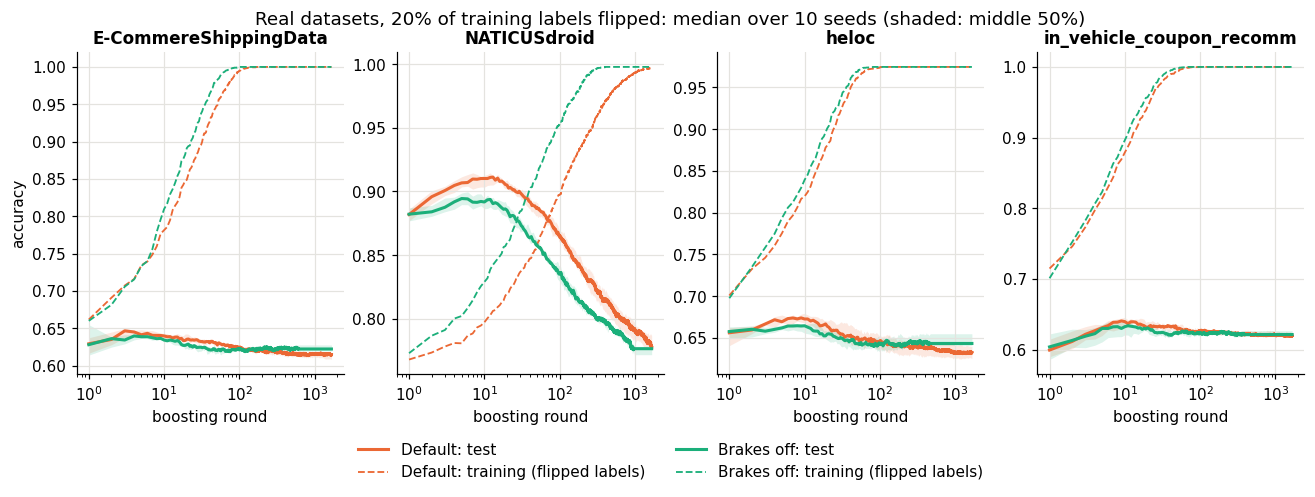

In [15]:
# Figure 4: real datasets with 20% flipped labels
names = sorted(real['data_name'].unique())
fig, axes = plt.subplots(1, len(names), figsize=(3.6 * len(names), 3.8), squeeze=False)

for ax, name in zip(axes[0], names):
    for setting in ['default', 'brakes_off']:
        group = real[(real['data_name'] == name) & (real['noise'] == 0.2) & (real['setting'] == setting)]
        if len(group) == 0:
            continue
        rounds, test_error = load_curve(group['run_id'], 'test_error')
        rounds, train_error = load_curve(group['run_id'], 'train_error')
        label, color = SETTING_NAMES[setting], SETTING_COLORS[setting]
        plot_median(ax, rounds, 1 - test_error, color, label + ': test')
        plot_median(ax, rounds, 1 - train_error, color, label + ': training (flipped labels)', dashed=True, band=False)
    ax.set_xscale('log')
    ax.set_xlabel('boosting round')
    ax.set_title(name[:24])

axes[0][0].set_ylabel('accuracy')
fig.legend(*axes[0][0].get_legend_handles_labels(), loc='upper center', bbox_to_anchor=(0.5, -0.02), ncol=2)
fig.suptitle('Real datasets, 20% of training labels flipped: median over 10 seeds (shaded: middle 50%)')
fig.savefig(FIG_DIR / 'fig4_real_datasets.png', dpi=150, bbox_inches='tight')
plt.show()

In **Figure 4**, each panel is one real dataset with 20% of the training labels flipped. Solid lines show test accuracy. Dashed lines show training accuracy measured on the labels the model was trained on, wrong ones included, so a dashed line at 1.0 means the model has memorized every label, including the flipped ones. As before, lines are medians over seeds and the x-axis is on a log scale.

**What we can see**

- **Test accuracy falls while the model memorizes the wrong labels.** NATICUSdroid shows this best: test accuracy peaks around round 10, then falls steadily as the dashed lines climb toward 1.0. The brakes-off model memorizes faster, and its test accuracy falls earlier.
- **Once memorizing is done, nothing changes.** On the other three datasets, the dashed lines reach their top by about round 100, and from then on test accuracy stays flat. It doesn't rise a second time, which is why we see no double descent here.
- **The useful learning happens in the first few rounds.** On every dataset, the best test accuracy comes long before memorization is finished.

**Takeaway on real data.** Here I see ordinary overfitting, not double descent. Test accuracy is best in the first few rounds, then falls as the model memorizes the flipped labels, and it doesn't recover. In terms of test error, this is the usual U or L shape, which is also what [Curth et al. (2023)](https://arxiv.org/abs/2310.18988) found for boosting rounds alone.

**What it means.** Double descent over rounds can happen in XGBoost, but only in a narrow setting: flipped labels, mainly with the brakes off, and mainly on synthetic data. Even then it is small, and on Friedman it doesn't beat stopping early.

## 4. Feature learning

Is there anything in boosting like the feature learning of neural networks?

The label is (a + b) mod 31. Knowing only a, or only b, tells you nothing about it. So a model can only get *unseen* pairs right if it builds something that combines a and b. I trained on half of all 961 pairs and tested on the other half, with five ways of writing a and b as input. The last one includes the column a + b, as a check that XGBoost can learn the task once it is given the right feature.

**Two baselines**
- Chance is 1/31 = 3.2%.
- A model that only memorizes "which labels went with this a, and with this b" scores **0%**, because for an unseen pair the correct label never appeared with that a or that b in training. So results near 0% mean memorization, not bad luck.

*Five ways of writing a and b as input:*
  1. **One-hot:** 31 columns for a and 31 for b, all 0 except a 1 in the column of the actual value.
  2. **Two integers:** a and b as two number columns.
  3. **Native categorical:** a and b as categories. XGBoost can then put any group of values on each side of a single split.
  4. **Sines and cosines:** each number turned into points on a circle at 15 different speeds (frequencies). Small transformers trained on this task have been found to represent the numbers this way ([Nanda et al., 2023](https://arxiv.org/abs/2301.05217)).
  5. **Two integers plus an a + b column (a control):** the model is given the combined feature directly. This checks that XGBoost can learn the task when it doesn't have to build the feature itself.

In [16]:
# Table 5: test accuracy on unseen pairs, by how a and b are written
modadd = runs[runs['task'] == 'modadd']

rows = []
for encoding, nice_name in ENCODING_NAMES.items():
    for setting in ['default', 'brakes_off']:
        group = modadd[(modadd['data_encoding'] == encoding) & (modadd['setting'] == setting)]
        if len(group) == 0:
            continue
        rows.append({
            'input': nice_name.replace('\n', ' '),
            'setting': SETTING_NAMES[setting],
            'best test accuracy (median)': group['best_test_acc'].median(),
            'final test accuracy (median)': group['final_test_acc'].median(),
            'memorizer baseline': group['memorizer_test_acc'].median(),
        })
show_table(pd.DataFrame(rows))

input,setting,best test accuracy (median),final test accuracy (median),memorizer baseline
One-hot,Default,0.015,0.000,0.000
One-hot,Brakes off,0.021,0.000,0.000
Two integers,Default,0.046,0.004,0.000
Two integers,Brakes off,0.033,0.008,0.000
Native categorical,Default,0.000,0.000,0.000
Native categorical,Brakes off,0.000,0.000,0.000
Sines and cosines,Default,0.004,0.000,0.000
Sines and cosines,Brakes off,0.002,0.000,0.000
Integers + a+b (control),Default,0.979,0.975,0.000
Integers + a+b (control),Brakes off,0.990,0.985,0.000




Each row is one way of writing a and b. The numbers are medians over 10 seeds, measured on the 241 test pairs.

- **With raw inputs, XGBoost does no better than memorizing.** Final accuracy is between 0% and 0.8%, below chance (3.2%) and close to the memorizer baseline (0%). With native categorical splits, even the best round scores 0%, exactly like the memorizer.
- **The best rounds aren't real learning either.** The highest is 4.6%, about 11 correct answers out of 241. Random guessing would get about 8.
- **The brakes make no difference.** Default and brakes-off runs fail the same way.
- **The task is easy once a + b is given.** With the a + b column, the same model reaches 98 to 99%. So XGBoost can learn the rule; it just doesn't build the a + b feature from the raw inputs on its own.

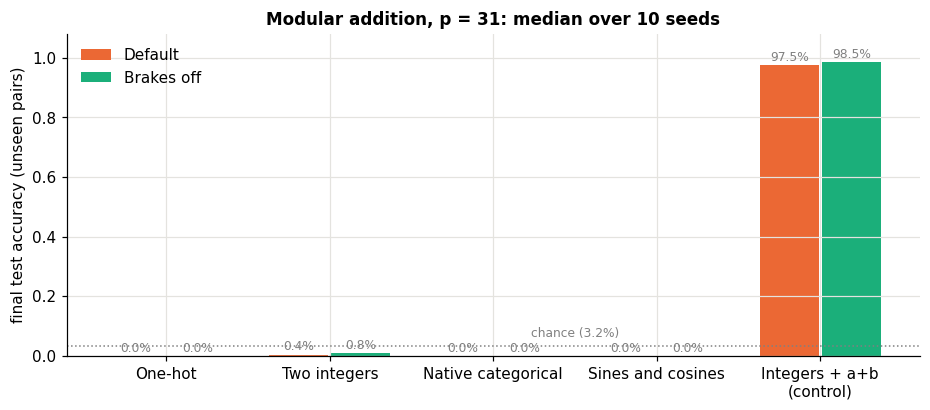

In [17]:
# Figure 5: final test accuracy on unseen pairs
fig, ax = plt.subplots(figsize=(10, 3.8))
width = 0.38

for i, setting in enumerate(['default', 'brakes_off']):
    values = [modadd[(modadd['data_encoding'] == e) & (modadd['setting'] == setting)]['final_test_acc'].median()
              for e in ENCODING_NAMES]
    x = np.arange(len(ENCODING_NAMES)) + (i - 0.5) * width
    ax.bar(x, values, width * 0.95, color=SETTING_COLORS[setting], label=SETTING_NAMES[setting])
    for xi, v in zip(x, values):
        ax.text(xi, v + 0.015, f'{v:.1%}', ha='center', fontsize=8, color='grey')

ax.axhline(1 / 31, color='grey', lw=1, ls=':')
ax.text(2.5, 1 / 31 + 0.03, 'chance (3.2%)', ha='center', fontsize=8, color='grey')
ax.set_xticks(range(len(ENCODING_NAMES)), list(ENCODING_NAMES.values()))
ax.set_ylim(0, 1.08)
ax.set_ylabel('final test accuracy (unseen pairs)')
ax.set_title('Modular addition, p = 31: median over 10 seeds')
ax.legend(loc='upper left')
fig.savefig(FIG_DIR / 'fig5_modular_addition.png', dpi=150, bbox_inches='tight')
plt.show()

**Figure 5** shows the final test accuracy from Table 5 as bars. Every raw way of writing a and b stays at or below the chance line (3.2%), while the a + b control is almost perfect. So XGBoost can learn the rule, but it can't build the feature it needs on its own.

**What it means.** XGBoost memorizes the training pairs but doesn't build the combined feature on its own, so on this task boosting shows no analogue of feature learning. This is the opposite of what [Mallinar et al. (2025)](https://arxiv.org/abs/2407.20199) found for Recursive Feature Machines, a non-neural method that keeps learning new input features as it trains, and which does grok modular addition.

## 5. Implications for RQ2 and RQ3

**RQ2: why do these things happen?** My proposal says that `min_child_weight` and `lambda` stop learning once the training data is memorized. Table 6 shows something more specific.

In [19]:
# Table 6: the last round in which any tree still made a split (median over runs)
groups = {
    'Parity, 100 rows': (runs['task'] == 'parity') & (runs['data_n'] == 100),
    'Parity, 300 rows': (runs['task'] == 'parity') & (runs['data_n'] == 300),
    'Parity, 1000 rows': (runs['task'] == 'parity') & (runs['data_n'] == 1000),
    'Friedman': runs['task'] == 'friedman',
    'Pilot 3 repeat': runs['task'] == 'skl_classification',
    'Modular addition': runs['task'] == 'modadd',
    'Real datasets (without SDSS17)': (runs['task'] == 'openml') & ~runs['data_name'].isin(SET_ASIDE),
}
rows = []
for name, mask in groups.items():
    group = runs[mask]
    if len(group) == 0:
        continue
    row = {'task': name, 'last round': int(group['rounds'].max())}
    for setting in SETTING_NAMES:
        row[SETTING_NAMES[setting]] = group[group['setting'] == setting]['last_round_with_split'].median()
    rows.append(row)
show_table(pd.DataFrame(rows), decimals=0)

task,last round,Default,Brakes off,Brakes off + weights x1000
"Parity, 100 rows",5000,5000,569,4958
"Parity, 300 rows",5000,5000,576,4990
"Parity, 1000 rows",5000,3254,434,4972
Friedman,1667,1667,246,-
Pilot 3 repeat,1667,1667,367,-
Modular addition,1667,1667,136,-
Real datasets (without SDSS17),1667,1667,467,-


Each cell is the last round in which a tree still made at least one split (median over runs). "Last round" is when training ended.

- **With the default settings, trees keep splitting until the last round**, except for parity with 1000 rows, where the pattern is fully learned.
- **With the brakes off, trees stop splitting much earlier, usually within a few hundred rounds.** With the weights multiplied by 1000 as well, they keep splitting almost to the end.
- **So the brakes-off runs are stopped by a third brake.** XGBoost refuses every split whose gain (how much the split would lower the training loss) is at most 10⁻⁶. This is a fixed number in its code (`kRtEps`), and after memorizing, the gains shrink below it. Multiplying the weights by 1000 makes every gain 1000 times larger without changing the leaf values, which is why those runs keep splitting.
- **This corrects my proposal.** Appendix A says "Setting both to zero removes these brakes", which is not true. The model of when learning freezes (T_freeze, the round after which trees stop making splits) has to include this third brake.
- **An open question.** The default runs keep splitting, yet with few rows they never learn parity. My guess, which I still need to test: with the defaults, `min_child_weight` blocks exactly the small leaves the hidden pattern needs. If so, "frozen" should mean "can't make the splits the pattern needs", not "makes no splits at all".



**RQ3: what does this mean for early stopping?**

In [20]:
# Table 7: on the noisy tasks, how good is the best round, and when does it come?
tasks = {
    'Friedman, 20% flipped': (runs['task'] == 'friedman') & (runs['noise'] == 0.2),
    'Pilot 3 repeat, 20% flipped': runs['task'] == 'skl_classification',
}
for name in sorted(real['data_name'].unique()):
    tasks[name + ', 20% flipped'] = (runs['data_name'] == name) & (runs['noise'] == 0.2)

rows = []
for name, mask in tasks.items():
    row = {'task': name}
    for setting in ['default', 'brakes_off']:
        group = runs[mask & (runs['setting'] == setting)]
        row[SETTING_NAMES[setting] + ': best test accuracy'] = group['best_test_acc'].median()
        row[SETTING_NAMES[setting] + ': best round'] = round(group['round_best_test_acc'].median())
    rows.append(row)
show_table(pd.DataFrame(rows))

task,Default: best test accuracy,Default: best round,Brakes off: best test accuracy,Brakes off: best round
"Friedman, 20% flipped",0.837,8,0.818,8
"Pilot 3 repeat, 20% flipped",0.846,22,0.844,324
"E-CommereShippingData, 20% flipped",0.648,4,0.645,4
"NATICUSdroid, 20% flipped",0.912,12,0.896,7
"heloc, 20% flipped",0.677,8,0.668,8
"in_vehicle_coupon_recommendation, 20% flipped",0.641,12,0.641,12


On every noisy task, the default model reaches its best test accuracy early, and training longer with the brakes off never beats it. So in these runs, stopping near the early peak would lose almost nothing. The cases RQ3 is really about, where the best round comes late, did happen on parity with few rows (Figure 1). That is where I should start comparing validation-based stopping and SESGB.